In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import mean_squared_error

import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

In [4]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/deep learning projects/Music Recommendation System/tcc_ceds_music.csv')
df.head()

,Unnamed: 0,artist_name,track_name,release_date,genre,lyrics,len,dating,violence,world/life,...,sadness,feelings,danceability,loudness,acousticness,instrumentalness,valence,energy,topic,age
0,0,mukesh,mohabbat bhi jhoothi,1950,pop,hold time feel break feel untrue convince spea...,95,0.000598,0.063746,0.000598,...,0.380299,0.117175,0.357739,0.454119,0.997992,0.901822,0.339448,0.137110,sadness,1.0
1,4,frankie laine,i believe,1950,pop,believe drop rain fall grow believe darkest ni...,51,0.035537,0.096777,0.443435,...,0.001284,0.001284,0.331745,0.647540,0.954819,0.000002,0.325021,0.263240,world/life,1.0
2,6,johnnie ray,cry,1950,pop,sweetheart send letter goodbye secret feel bet...,24,0.002770,0.002770,0.002770,...,0.002770,0.225422,0.456298,0.585288,0.840361,0.000000,0.351814,0.139112,music,1.0
3,10,pérez prado,patricia,1950,pop,kiss lips want stroll charm mambo chacha merin...,54,0.048249,0.001548,0.001548,...,0.225889,0.001548,0.686992,0.744404,0.083935,0.199393,0.775350,0.743736,romantic,1.0
4,12,giorgos papadopoulos,apopse eida oneiro,1950,pop,till darling till matter know till dream live ...,48,0.001350,0.001350,0.417772,...,0.068800,0.001350,0.291671,0.646489,0.975904,0.000246,0.597073,0.394375,romantic,1.0


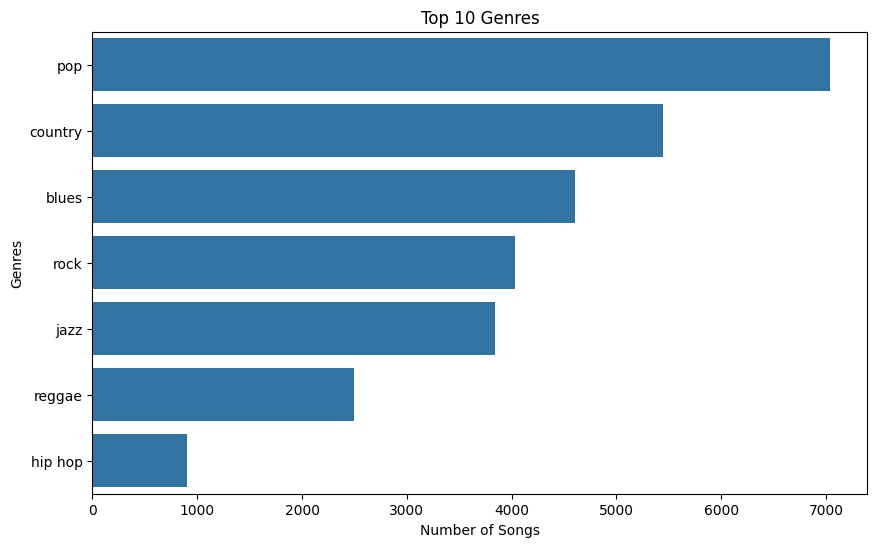

In [5]:
plt.figure(figsize=(10,6))
sns.countplot(y='genre', data=df, order=df['genre'].value_counts().index[:10])
plt.title('Top 10 Genres')
plt.xlabel('Number of Songs')
plt.ylabel('Genres')
plt.show()

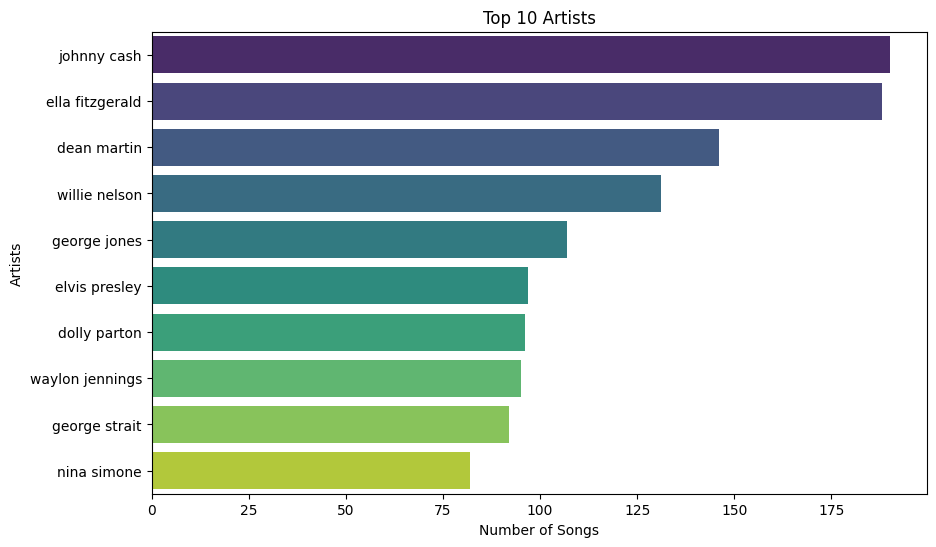

In [6]:
top_artists = df.groupby('artist_name').size().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,6))
sns.barplot(x=top_artists.values, y=top_artists.index, palette='viridis')
plt.title('Top 10 Artists')
plt.xlabel('Number of Songs')
plt.ylabel('Artists')
plt.show()

In [7]:
df['combined_features'] = (
    df['genre'].fillna('') + ' ' +
    df['artist_name'].fillna('') + ' ' +
    df['track_name'].fillna('')
)
df.head()

,Unnamed: 0,artist_name,track_name,release_date,genre,lyrics,len,dating,violence,world/life,...,feelings,danceability,loudness,acousticness,instrumentalness,valence,energy,topic,age,combined_features
0,0,mukesh,mohabbat bhi jhoothi,1950,pop,hold time feel break feel untrue convince spea...,95,0.000598,0.063746,0.000598,...,0.117175,0.357739,0.454119,0.997992,0.901822,0.339448,0.137110,sadness,1.0,pop mukesh mohabbat bhi jhoothi
1,4,frankie laine,i believe,1950,pop,believe drop rain fall grow believe darkest ni...,51,0.035537,0.096777,0.443435,...,0.001284,0.331745,0.647540,0.954819,0.000002,0.325021,0.263240,world/life,1.0,pop frankie laine i believe
2,6,johnnie ray,cry,1950,pop,sweetheart send letter goodbye secret feel bet...,24,0.002770,0.002770,0.002770,...,0.225422,0.456298,0.585288,0.840361,0.000000,0.351814,0.139112,music,1.0,pop johnnie ray cry
3,10,pérez prado,patricia,1950,pop,kiss lips want stroll charm mambo chacha merin...,54,0.048249,0.001548,0.001548,...,0.001548,0.686992,0.744404,0.083935,0.199393,0.775350,0.743736,romantic,1.0,pop pérez prado patricia
4,12,giorgos papadopoulos,apopse eida oneiro,1950,pop,till darling till matter know till dream live ...,48,0.001350,0.001350,0.417772,...,0.001350,0.291671,0.646489,0.975904,0.000246,0.597073,0.394375,romantic,1.0,pop giorgos papadopoulos apopse eida oneiro


In [8]:
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(df['combined_features'])

cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

def get_recommendations(track_name, cosine_sim=cosine_sim, top_n=10):
  idx = df[df['track_name'] == track_name].index
  if len(idx) == 0:
    print('Track not found in the dataset.')
    return

  idx = idx[0]
  sim_scores = list(enumerate(cosine_sim[idx]))
  sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
  sim_scores = sim_scores[1:top_n+1]
  song_indices = [i[0] for i in sim_scores]

  recommendations = df.iloc[song_indices]

  return recommendations


In [11]:
input_track_name = 'smile'
recommended_songs = get_recommendations(input_track_name, cosine_sim)
print(recommended_songs[['track_name', 'artist_name', 'genre']])

                      track_name  artist_name genre
232                 walk with me  neil sedaka   pop
303            all i need is you  neil sedaka   pop
277    you mean everything to me  neil sedaka   pop
298           i must be dreaming  neil sedaka   pop
222              i belong to you  neil sedaka   pop
360             sweet little you  neil sedaka   pop
233            as long as i live  neil sedaka   pop
223  crying my heart out for you  neil sedaka   pop
234            the same old fool  neil sedaka   pop
408   all the words in the world  neil sedaka   pop


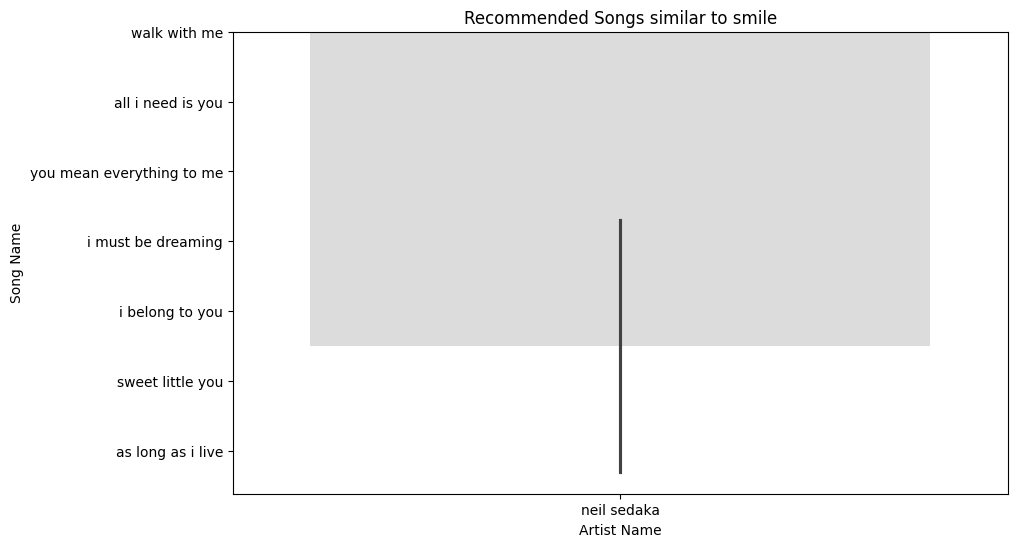

In [13]:
plt.figure(figsize=(10,6))
sns.barplot(y='track_name', x='artist_name', data=recommended_songs, palette='coolwarm')
plt.title(f'Recommended Songs similar to {input_track_name}')
plt.xlabel('Artist Name')
plt.ylabel('Song Name')
plt.show()